# Ulta Setting Spray: Pricing, Value & Market Segmentation

**Data:** 160 Ulta setting spray listings (brand, product, price, size in oz, \$/oz, finish, size tier)

**Questions**
1. Is there a "small-size tax," and does it vary by brand?
2. Do finishes (Matte, Dewy, Natural, Hydrate, Radiant) carry a price premium?
3. Which brands are budget vs. prestige?
4. Do the products fall into natural market tiers (clustering)?

**Size tier rule:** one size → Medium; three sizes → Small/Medium/Large; two sizes → Small and Large; a mini → Small.

In [2]:
import warnings; warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.width', 200)

df = pd.read_csv('Ulta Setting Spray 2026.csv')
df = df.rename(columns={'$/OZ': 'ppo', 'Finish Type': 'Finish', 'Size type': 'SizeTier'})
df.shape

(160, 8)

## Cleaning & validation

In [3]:
# Whitespace / typo checks
for c in ['Brand','Name','Finish','SizeTier']:
    df[c] = df[c].str.strip()
print('Missing values:', df.isna().sum().sum())
print('Exact duplicate rows:', df.duplicated().sum())
print('Rows where Price/Size disagrees with $/oz by >2c:', (abs(df.Price/df.Size - df.ppo) > 0.02).sum())

df = df.drop_duplicates().reset_index(drop=True)
df['SizeTier'] = pd.Categorical(df['SizeTier'], ['Small','Medium','Large'], ordered=True)
print('Rows after de-duplication:', len(df))
df.to_csv('setting_spray_clean.csv', index=False)   # use this file in Tableau
df.describe().round(2)

Missing values: 0
Exact duplicate rows: 4
Rows where Price/Size disagrees with $/oz by >2c: 0
Rows after de-duplication: 156


,Price,Size,ppo
count,156.00,156.00,156.00
mean,21.53,2.78,9.09
std,11.38,1.49,5.40
min,4.00,0.60,2.20
25%,13.00,1.69,4.35
50%,18.00,2.70,8.06
75%,32.00,3.40,11.54
max,59.00,10.14,27.00


The duplicates are exact repeats (Charlotte Tilbury and Morphe each have a Small and Large listed twice), so they were dropped.

**Caveat on the size tiers:** `Medium` mixes two different things: the middle size of a 3-size ladder *and* products that only come in one size. Single-size products skew toward drugstore brands, which is why Medium looks cheapest. Keep this in mind when reading tier results; the cleanest "small-size tax" comparison is Small vs. Large.

## Exploratory analysis

59 brands | 119 unique products


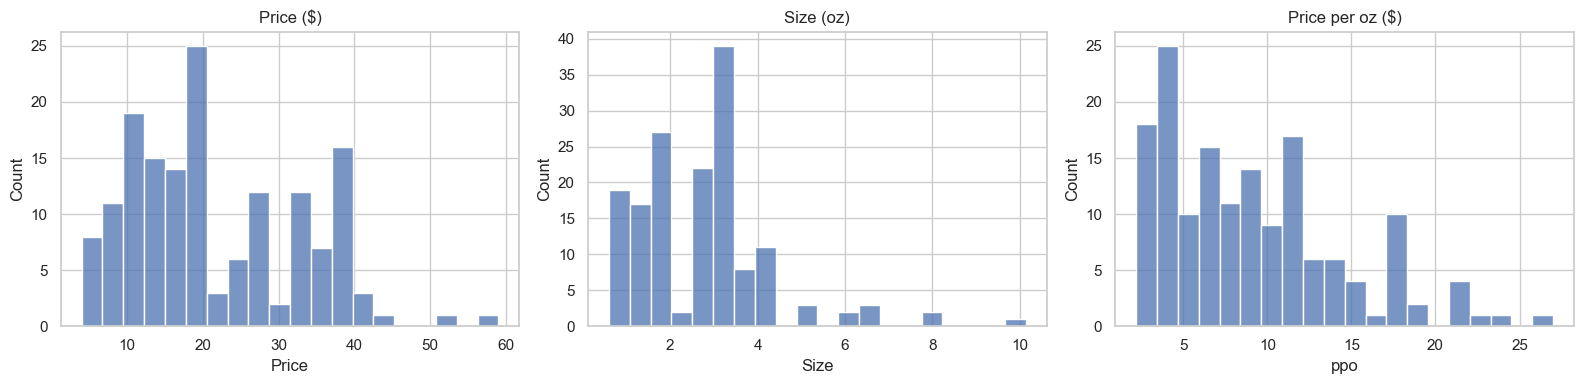

       Price  Size   ppo
Price   1.00  0.41  0.59
Size    0.41  1.00 -0.45
ppo     0.59 -0.45  1.00


In [4]:
print(df.Brand.nunique(), 'brands |', df.Name.nunique(), 'unique products')
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df.Price, bins=20, ax=ax[0]); ax[0].set_title('Price ($)')
sns.histplot(df.Size, bins=20, ax=ax[1]); ax[1].set_title('Size (oz)')
sns.histplot(df.ppo, bins=20, ax=ax[2]); ax[2].set_title('Price per oz ($)')
plt.tight_layout(); plt.show()
print(df[['Price','Size','ppo']].corr(method='spearman').round(2))

## Is there a small-size tax?

,count,median,mean,std
SizeTier,,,,
Small,37,14.41,14.32,5.46
Medium,86,5.78,6.95,4.16
Large,33,8.81,8.80,4.19


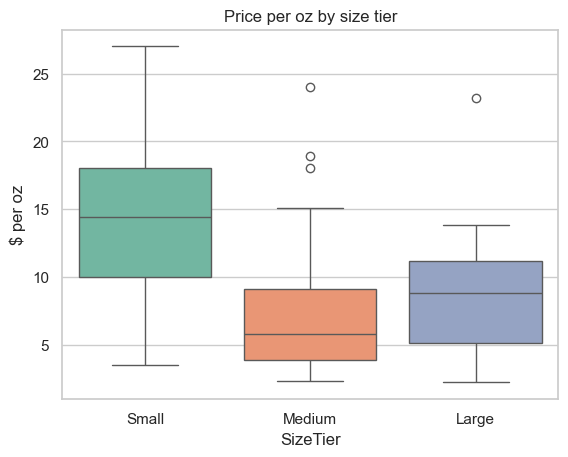

Kruskal-Wallis across tiers: H=43.7, p=3.21e-10
Small vs Large (one-sided Mann-Whitney): p=1.84e-05; median Small/Large = 1.64x


In [5]:
g = df.groupby('SizeTier', observed=True).ppo.agg(['count','median','mean','std']).round(2)
display(g)
sns.boxplot(data=df, x='SizeTier', y='ppo', palette='Set2'); plt.ylabel('$ per oz'); plt.title('Price per oz by size tier'); plt.show()

h, p = stats.kruskal(*[x.ppo.values for _, x in df.groupby('SizeTier', observed=True)])
print(f'Kruskal-Wallis across tiers: H={h:.1f}, p={p:.2e}')
sm, lg = df[df.SizeTier=='Small'].ppo, df[df.SizeTier=='Large'].ppo
u, p2 = stats.mannwhitneyu(sm, lg, alternative='greater')
print(f'Small vs Large (one-sided Mann-Whitney): p={p2:.2e}; median Small/Large = {sm.median()/lg.median():.2f}x')

### Small-size tax by brand

Only brands that sell both a Small and a Large are compared. Ratio = median Small \$/oz ÷ median Large \$/oz.

SizeTier,Small,Medium,Large,small_tax_ratio
Brand,,,,
Tarte,13.46,NaN,15.60,0.86
Kopari Beauty,11.76,NaN,13.44,0.88
Naked Sundays,12.86,NaN,10.63,1.21
MILK MAKEUP,15.99,NaN,12.17,1.31
NYX Professional Makeup,6.67,4.93,4.95,1.35
Rare Beauty,14.41,NaN,10.45,1.38
FENTY BEAUTY by Rihanna,14.41,NaN,9.71,1.48
SACHEU,10.00,NaN,6.67,1.50
DIBS Beauty,20.88,NaN,13.79,1.51


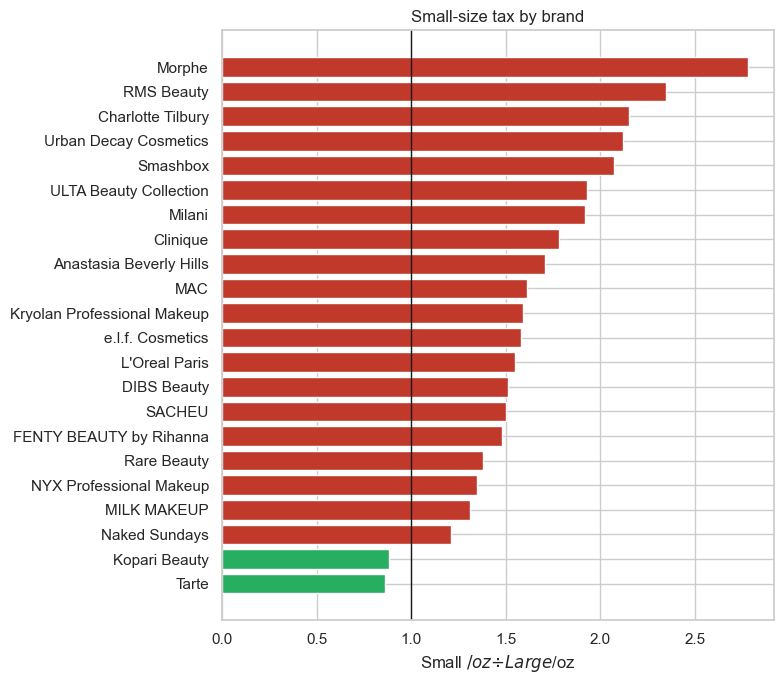

Brands where Small costs more per oz: 20 of 22


In [6]:
piv = df.pivot_table(index='Brand', columns='SizeTier', values='ppo', aggfunc='median', observed=True)
tax = piv.dropna(subset=['Small','Large']).copy()
tax['small_tax_ratio'] = (tax.Small / tax.Large).round(2)
tax = tax.sort_values('small_tax_ratio')
display(tax.round(2))

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(tax.index, tax.small_tax_ratio, color=np.where(tax.small_tax_ratio>1,'#c0392b','#27ae60'))
ax.axvline(1, color='k', lw=1); ax.set_xlabel('Small $/oz ÷ Large $/oz'); ax.set_title('Small-size tax by brand')
plt.tight_layout(); plt.show()
print('Brands where Small costs more per oz:', (tax.small_tax_ratio>1).sum(), 'of', len(tax))

## Do finishes carry a premium?

,count,median,mean
Finish,,,
Matte,29,6.00,8.40
Dewy,19,7.43,8.49
Natural,59,8.00,9.11
Hydrate,36,9.31,9.60
Radiant,13,11.11,10.00


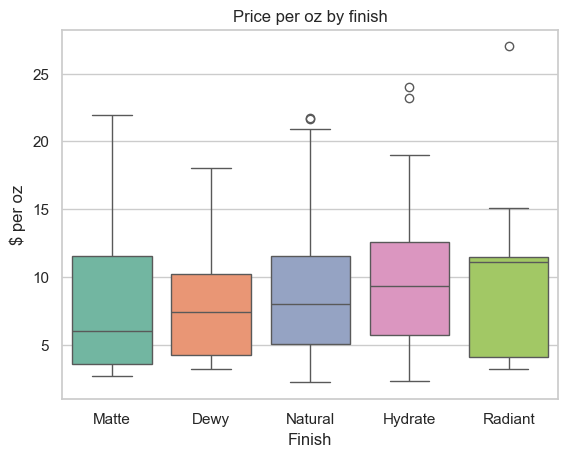

Kruskal-Wallis across finishes: H=2.17, p=0.704
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                 2.5367      0.138     18.342      0.000       2.263       2.810
C(Finish)[T.Hydrate]      0.2178      0.146      1.488      0.139      -0.072       0.507
C(Finish)[T.Matte]       -0.0735      0.152     -0.484      0.629      -0.373       0.226
C(Finish)[T.Natural]      0.0174      0.136      0.128      0.899      -0.251       0.286
C(Finish)[T.Radiant]      0.3219      0.187      1.722      0.087      -0.048       0.691
C(SizeTier)[T.Medium]    -0.8490      0.104     -8.188      0.000      -1.054      -0.644
C(SizeTier)[T.Large]     -0.5160      0.123     -4.193      0.000      -0.759      -0.273


                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                 2.5367      0.138     18.342      0.000       2.263       2.810
C(Finish)[T.Hydrate]      0.2178      0.146      1.488      0.139      -0.072       0.507
C(Finish)[T.Matte]       -0.0735      0.152     -0.484      0.629      -0.373       0.226
C(Finish)[T.Natural]      0.0174      0.136      0.128      0.899      -0.251       0.286
C(Finish)[T.Radiant]      0.3219      0.187      1.722      0.087      -0.048       0.691
C(SizeTier)[T.Medium]    -0.8490      0.104     -8.188      0.000      -1.054      -0.644
C(SizeTier)[T.Large]     -0.5160      0.123     -4.193      0.000      -0.759      -0.273


In [7]:
display(df.groupby('Finish').ppo.agg(['count','median','mean']).round(2).sort_values('median'))
sns.boxplot(data=df, x='Finish', y='ppo', palette='Set2', order=df.groupby('Finish').ppo.median().sort_values().index)
plt.ylabel('$ per oz'); plt.title('Price per oz by finish'); plt.show()

h, p = stats.kruskal(*[x.ppo.values for _, x in df.groupby('Finish')])
print(f'Kruskal-Wallis across finishes: H={h:.2f}, p={p:.3f}')

# Does finish matter after controlling for size tier and price level? OLS on log $/oz
import statsmodels.formula.api as smf
m = smf.ols('np.log(ppo) ~ C(Finish) + C(SizeTier)', data=df).fit()
print(m.summary().tables[1])

## Budget vs. prestige brands

,n,median_ppo,median_price,segment
Brand,,,,
Essence,4,2.95,4.99,Budget
L.A. Girl,6,3.14,9.00,Budget
Revolution Beauty,6,3.18,14.00,Budget
ULTA Beauty Collection,6,3.85,13.00,Budget
J. Cat Beauty,3,4.00,7.99,Budget
e.l.f. Cosmetics,10,4.07,11.00,Budget
NYX Professional Makeup,5,4.95,10.00,Mid-range
Milani,8,6.89,17.74,Mid-range
Morphe,8,7.14,19.00,Mid-range


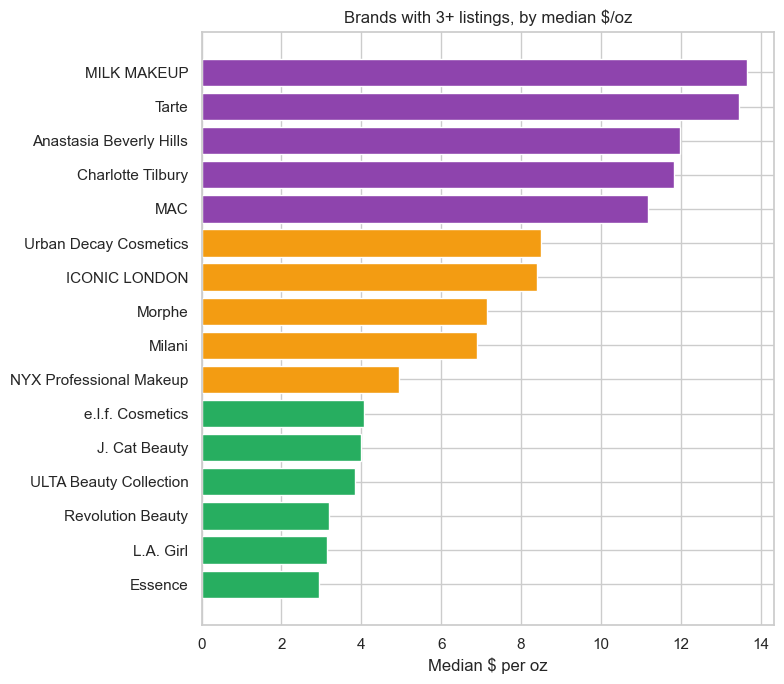

In [8]:
brand = (df.groupby('Brand').agg(n=('ppo','size'), median_ppo=('ppo','median'), median_price=('Price','median'))
           .query('n >= 3').sort_values('median_ppo'))
q1, q2 = brand.median_ppo.quantile([1/3, 2/3])
brand['segment'] = pd.cut(brand.median_ppo, [0, q1, q2, 99], labels=['Budget','Mid-range','Prestige'])
display(brand.round(2))

fig, ax = plt.subplots(figsize=(8, 7))
colors = brand.segment.map({'Budget':'#27ae60','Mid-range':'#f39c12','Prestige':'#8e44ad'})
ax.barh(brand.index, brand.median_ppo, color=colors); ax.set_xlabel('Median $ per oz')
ax.set_title('Brands with 3+ listings, by median $/oz'); plt.tight_layout(); plt.show()

## Market segmentation (clustering)

Price, size and \$/oz are mathematically linked (\$/oz = price ÷ size), so clustering on all three would double-count. I cluster on **log(price)** and **log(price per oz)**, which together carry the same information as price and size, and standardize them since both are right-skewed.

,k,inertia,silhouette
0,2,119.051,0.520
1,3,86.039,0.477
2,4,56.454,0.475
3,5,45.189,0.472
4,6,37.906,0.458
5,7,33.271,0.447


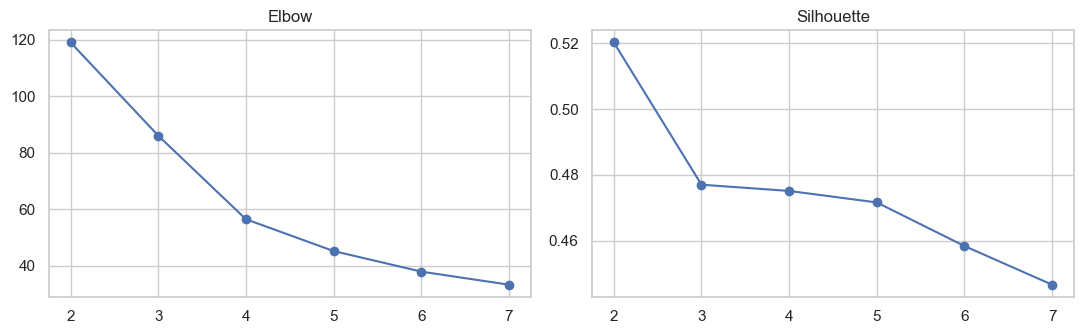

In [9]:
X = StandardScaler().fit_transform(np.log(df[['Price','ppo']]))

res = []
for k in range(2, 8):
    km = KMeans(k, n_init=20, random_state=42).fit(X)
    res.append((k, km.inertia_, silhouette_score(X, km.labels_)))
res = pd.DataFrame(res, columns=['k','inertia','silhouette'])
display(res.round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(res.k, res.inertia, 'o-'); ax[0].set_title('Elbow')
ax[1].plot(res.k, res.silhouette, 'o-'); ax[1].set_title('Silhouette')
plt.tight_layout(); plt.show()

In [10]:
K = 4  # chosen from the elbow/silhouette above; adjust if you prefer a different k
km = KMeans(K, n_init=50, random_state=42).fit(X)
df['cluster'] = km.labels_

# Agglomerative clustering as a robustness check
agg = AgglomerativeClustering(K, linkage='ward').fit(X)
from sklearn.metrics import adjusted_rand_score
print('Agreement k-means vs. hierarchical (ARI):', round(adjusted_rand_score(km.labels_, agg.labels_), 2))

# Order clusters by median $/oz and name them
order = df.groupby('cluster').ppo.median().sort_values().index
names = dict(zip(order, ['Value','Everyday','Premium','Small / mini sizes'][:K]))
df['segment'] = df.cluster.map(names)
prof = df.groupby('segment').agg(n=('ppo','size'), median_price=('Price','median'), median_size=('Size','median'),
                                 median_ppo=('ppo','median')).sort_values('median_ppo').round(2)
display(prof)

Agreement k-means vs. hierarchical (ARI): 0.87


,n,median_price,median_size,median_ppo
segment,,,,
Value,41,9.99,2.70,3.85
Everyday,34,18.00,2.80,5.92
Premium,48,36.00,3.40,10.61
Small / mini sizes,33,18.00,1.15,17.78


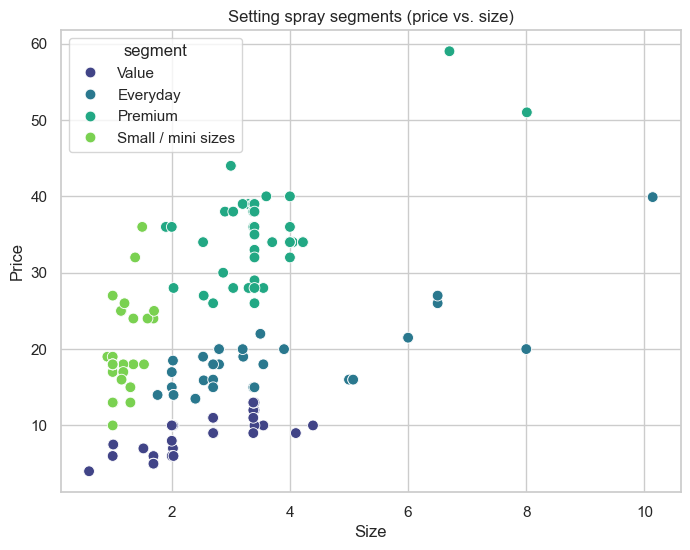

Finish mix by segment (row %):


Finish,Dewy,Hydrate,Matte,Natural,Radiant
segment,,,,,
Value,17.0,22.0,29.0,24.0,7.0
Everyday,15.0,12.0,15.0,53.0,6.0
Premium,8.0,29.0,15.0,35.0,12.0
Small / mini sizes,9.0,27.0,15.0,42.0,6.0


Size tier mix by segment (row %):


SizeTier,Small,Medium,Large
segment,,,
Value,10.0,83.0,7.0
Everyday,12.0,65.0,24.0
Premium,0.0,56.0,44.0
Small / mini sizes,88.0,9.0,3.0



Value: e.l.f. Cosmetics (9), L.A. Girl (6), ULTA Beauty Collection (6), NYX Professional Makeup (5), Essence (4), J. Cat Beauty (3)

Everyday: Milani (8), Morphe (5), Revolution Beauty (3), BLK/OPL (2), Juvia's Place (2), Kryolan Professional Makeup (2)

Premium: Urban Decay Cosmetics (4), MAC (4), ICONIC LONDON (3), Charlotte Tilbury (3), PAT McGRATH LABS (2), MILK MAKEUP (2)

Small / mini sizes: Urban Decay Cosmetics (3), Tarte (3), Morphe (3), MAC (3), ICONIC LONDON (2), Anastasia Beverly Hills (2)


In [11]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=df, x='Size', y='Price', hue='segment', hue_order=prof.index, palette='viridis', s=60, ax=ax)
ax.set_title('Setting spray segments (price vs. size)'); plt.show()

print('Finish mix by segment (row %):')
display((pd.crosstab(df.segment, df.Finish, normalize='index')*100).loc[prof.index].round(0))
print('Size tier mix by segment (row %):')
display((pd.crosstab(df.segment, df.SizeTier, normalize='index')*100).loc[prof.index].round(0))
for s in prof.index:
    top = df[df.segment==s].Brand.value_counts().head(6)
    print(f'\n{s}:', ', '.join(f'{b} ({n})' for b, n in top.items()))

In [12]:
df.to_csv('setting_spray_clustered.csv', index=False)   # import into Tableau

## 7. Key findings

- **Small-size tax is real:** median Small \$/oz (~\$14.41) is about 1.6x Large (~\$8.81); significant (Mann-Whitney p < 0.001). Small costs more per oz than Large for 20 of 22 brands that sell both. The tax is steepest at Morphe, RMS Beauty, Charlotte Tilbury, and Urban Decay (about 2.1-2.8x) and absent at Tarte and Kopari.
- **Finish does not drive price:** Kruskal-Wallis p = 0.70, and no finish is significant in the log-price regression after controlling for size tier. Radiant and Hydrate have higher medians, but the differences are within noise.
- **Brand is the real price driver:** Budget (Essence, L.A. Girl, Revolution, ULTA Collection, e.l.f.) vs. Prestige (MAC, Charlotte Tilbury, Anastasia Beverly Hills, Tarte, Milk Makeup) is a roughly 3-4x gap in median \$/oz.
- **Segments (k=4):** Value (\$10, \$3.85/oz), Everyday (\$18, \$5.92/oz), Premium (\$36, \$10.61/oz), and Small / mini sizes (1.15 oz, \$17.78/oz). The fourth cluster is defined by bottle size, not brand tier: prestige brands' travel sizes land there, which is the small-size tax showing up in the clusters. Silhouette is highest at k=2 (0.52) but k=4 is nearly as good (0.48) and far more interpretable; k-means and hierarchical agree (ARI 0.87).

## 8. Limitations

- One retailer (Ulta), one snapshot in time (2026); prices change with promotions.
- Small sample (156 listings, 59 brands); many brands have only 1-3 listings.
- Size tiers were assigned by rule rather than measured; `Medium` mixes single-size products with mid-size ladder entries.
- No sales or rating data, so "value" here means price per oz, not quality or popularity.